# Projekt 1 — diagnostyka procesu uczenia sieci neuronowej

## Cel projektu

Zbuduj i zbadaj klasyfikator oparty na wielowarstwowej sieci neuronowej (MLP) dla syntetycznych danych w kształcie dwóch zaszumionych półksiężyców. Twoim zadaniem nie jest wyłącznie uzyskać dobry wynik, lecz **rozpoznać problemy uczenia, zaprojektować kontrolowany eksperyment i uzasadnić wnioski danymi**.

W projekcie pokaż niedouczenie i przeuczenie, a następnie zbadaj, czy regularyzacja przez dropout ogranicza przeuczenie.

## Zadanie w skrócie

1. Wygeneruj ustalony zbiór danych i podziel go na treningowy, walidacyjny i testowy.
2. Przygotuj proste baseline’y oraz MLP spełniający wymagania minimalne.
3. Zademonstruj niedouczenie i przeuczenie, wyjaśniając, po czym je rozpoznajesz.
4. Przeprowadź kontrolowane porównanie trzech wartości dropout.
5. Porównaj wyniki na walidacji, wybierz konfigurację i dopiero na końcu oceń ją na zbiorze testowym.
6. Przedstaw wykresy i krótki raport z wnioskami.

## 1. Dane i podział

Użyj zbioru **1200 przykładów** klasyfikacji binarnej w kształcie dwóch półksiężyców. Ustalony poziom szumu to `0.25`, a ziarno generatora danych to `42`. Zbiór powinien mieć dwie cechy wejściowe oraz etykiety klas 0 i 1.

Wykonaj stratyfikowany podział: **70% trening / 15% walidacja / 15% test**. Zapisz sposób podziału i ziarna losowe, by eksperyment można było odtworzyć. Pokaż wykres punktowy danych z oznaczeniem klas i zbiorów.

### Zapobieganie wyciekowi danych

Jeśli skalujesz cechy, dopasuj skalowanie wyłącznie na zbiorze treningowym. Tego samego dopasowanego transformera użyj do przekształcenia walidacji i testu. Nie dopasowuj transformacji ponownie na całości danych. Zbioru testowego nie używaj podczas doboru modelu, hiperparametrów ani epoki.

> *Hiperparametry modelu liniowego: learning rate = (0.05, 0.01), rozmiar partii = 1200, liczba epok = (25, 100), liczba warstw = 1, liczba neuronów = 1*





In [403]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import seaborn as sns
sns.set()

In [404]:
#Funkcje


def make_moons_dataset (n_samples=1200, noise=0.25, seed=42):
  return make_moons(n_samples=n_samples, noise=noise, random_state=seed)


def train_val_test_split(X, y, train_ratio=0.7, val_ratio=0.15, seed=42):

  X_train, X_val_and_test, y_train, y_val_and_test = train_test_split(
      X, y, train_size=train_ratio, stratify=y, random_state=seed)
  val_relative = val_ratio / (1 - train_ratio)
  X_val, X_test, y_val, y_test = train_test_split(
      X_val_and_test, y_val_and_test, train_size=val_relative, stratify=y_val_and_test, random_state=seed)

  return (X_train, y_train, X_val, y_val, X_test, y_test)


def fit_standardizer(X_train):
  mean = X_train.mean(axis=0, keepdims=True)
  std = X_train.std(axis=0, keepdims=True)
  std = np.where(std == 0, 1.0, std)
  return mean, std


def transform_standardizer(X, mean, std):
  return (X - mean) / std

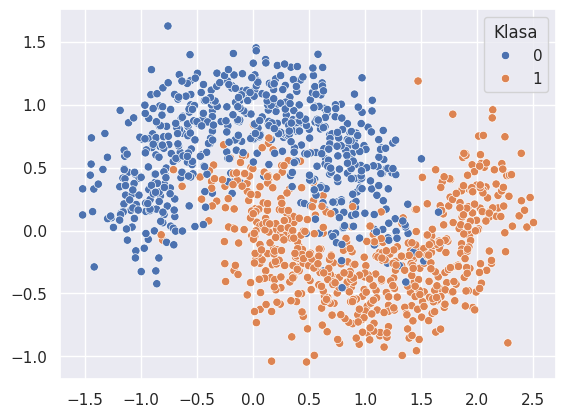

In [405]:
#Generacja

X, y = make_moons_dataset(n_samples=1200, noise=0.25, seed=42)
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y);
plt.legend(title="Klasa")

X_train, y_train, X_val, y_val, X_test, y_test = train_val_test_split(X, y, train_ratio=0.7, val_ratio=0.15, seed=42)

mean, std = fit_standardizer(X_train)
X_train_scaled = transform_standardizer(X_train, mean, std)
X_val_scaled = transform_standardizer(X_val, mean, std)
X_test_scaled = transform_standardizer(X_test, mean, std)

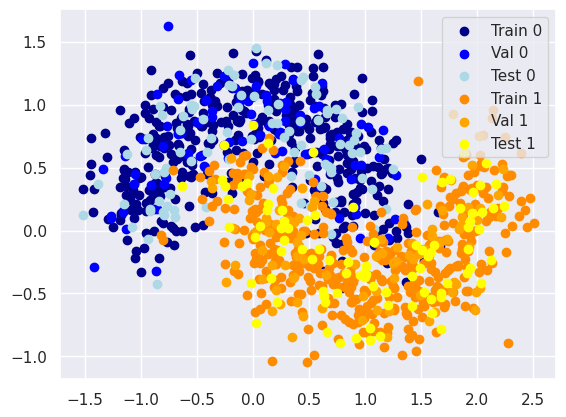

In [406]:
import matplotlib.pyplot as plt

plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color="darkblue", label="Train 0")
plt.scatter(X_val[y_val == 0, 0], X_val[y_val == 0, 1], color="blue", label="Val 0")
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], color="lightblue", label="Test 0")

plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color="darkorange", label="Train 1")
plt.scatter(X_val[y_val == 1, 0], X_val[y_val == 1, 1], color="orange", label="Val 1")
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], color="yellow", label="Test 1")

plt.legend()
plt.show()

## 2. Baseline’y i diagnoza niedouczenia

Przygotuj dwa punkty odniesienia:

- **Baseline naiwny:** klasyfikator przewidujący zawsze klasę większościową. Służy do sprawdzenia, czy model daje wartość ponad prostą regułę.
- **Model liniowy:** np. regresja logistyczna. Użyj go do zilustrowania niedouczenia: liniowa granica decyzyjna może nie oddać nieliniowego kształtu półksiężyców.

Oceń oba modele na zbiorze walidacyjnym, używając accuracy i F1. Pokaż granice decyzyjne. Wyjaśnij, dlaczego model liniowy nie jest tu równoważny z MLP. Nie wykorzystuj zbioru testowego do tej analizy.

In [407]:
#Baseline naiwny

def majority_baseline_predict(y_train, n_examples):
  counts = np.bincount(y_train)
  majority_class = np.argmax(counts)
  return np.full(shape=n_examples, fill_value=majority_class, dtype=np.int64)


#Perceptron
class Perceptron:
    def __init__(self, n_features, learning_rate=0.1, seed=42):
        rng = np.random.default_rng(seed)
        self.w = rng.normal(loc=0.0, scale=0.01, size=n_features)
        self.b = 0.0
        self.learning_rate = learning_rate

    def net(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        z = self.net(X)
        return (z >= 0).astype(np.int64)

    def fit(self, X, y, epochs=60):
        history = []

        for epoch in range(epochs):
            errors = 0

            for x_i, y_i in zip(X, y):
                y_pred = self.predict(x_i.reshape(1, -1))[0]
                update = self.learning_rate * (y_i - y_pred)

                if update != 0:
                    self.w += update * x_i
                    self.b += update
                    errors += 1

            history.append({"epoch": epoch + 1, "errors": errors})

        return history

In [408]:
#Metryki


def safe_divide(numerator, denominator):
    return numerator / denominator if denominator != 0 else 0.0


def metrics_binary (y, y_pred):

  tp, tn, fp, fn = 0, 0, 0, 0

  for i in range(len(y)):
    if y[i]+y_pred[i]==0: tn+=1
    elif (y[i]+y_pred[i]==1)and(y_pred[i]==0): fn+=1
    elif (y[i]+y_pred[i]==1)and(y_pred[i]==1): fp+=1
    else: tp+=1

  metrics = {'TP':tp, 'TN':tn, 'FP':fp, 'FN':fn}
  metrics['accuracy'] = safe_divide(tp+tn, tp+tn+fp+fn)
  metrics['recall'] = recall = safe_divide(tp, fn+tp)
  metrics['precision'] = precision = safe_divide(tp, fp+tp)
  metrics['f1'] = safe_divide(2*recall*precision, recall+precision)

  return metrics

In [409]:
#Generacja

y_baseline = majority_baseline_predict(y_train, len(y_val))
print(metrics_binary(y_val, y_baseline))

line_model1 = Perceptron(n_features=2, learning_rate=0.05, seed=42)
history1 = line_model1.fit(X_train_scaled, y_train, epochs=60)
val_pred1 = line_model1.predict(X_val_scaled)
print(metrics_binary(y_val, val_pred1))

line_model2 = Perceptron(n_features=2, learning_rate=0.01, seed=42)
history2 = line_model2.fit(X_train_scaled, y_train, epochs=100)
val_pred2 = line_model2.predict(X_val_scaled)
print(metrics_binary(y_val, val_pred2))

{'TP': 0, 'TN': 89, 'FP': 0, 'FN': 90, 'accuracy': 0.4972067039106145, 'recall': 0.0, 'precision': 0.0, 'f1': 0.0}
{'TP': 61, 'TN': 84, 'FP': 5, 'FN': 29, 'accuracy': 0.8100558659217877, 'recall': 0.6777777777777778, 'precision': 0.9242424242424242, 'f1': 0.7820512820512822}
{'TP': 75, 'TN': 79, 'FP': 10, 'FN': 15, 'accuracy': 0.8603351955307262, 'recall': 0.8333333333333334, 'precision': 0.8823529411764706, 'f1': 0.8571428571428571}


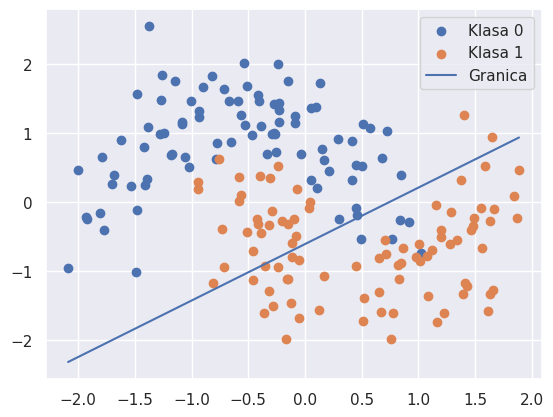

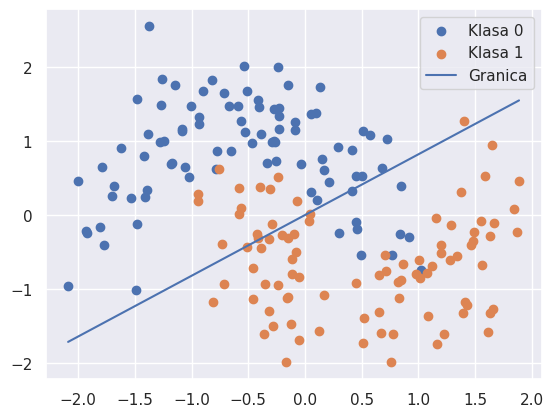

In [410]:
#Wykresy

def plot_decision_boundary(model, X, y):
  plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Klasa 0")
  plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Klasa 1")

  x1 = np.linspace(X[:, 0].min(), X[:, 0].max())
  x2 = -(model.w[0] * x1 + model.b) / model.w[1]

  plt.plot(x1, x2, label="Granica")
  plt.legend()
  plt.show()

plot_decision_boundary(line_model1, X_val_scaled, y_val)
plot_decision_boundary(line_model2, X_val_scaled, y_val)

> *Baseline większościowy nie posiada granicy decyzyjnej - dla każdego punktu przewiduje tę samą klasę*



> *Wizualną rzeczywistą granicą decyzyjną dwóch klass jest krzywa dzilące je na 2 obszary jest krzywa. Pojedyncza funkcja liniowa nie jest w stanie tego zobrazować, co zostało zademonstrowane na wykresach*



## 3. Wymagania minimalne dla MLP

Zbuduj klasyfikator o następujących cechach:

- wejście przyjmuje dwie cechy;
- co najmniej **dwie warstwy ukryte**, każda z co najmniej **32 neuronami**;
- warstwy ukryte korzystają z aktywacji ReLU;
- warstwa wyjściowa ma jeden neuron z aktywacją sigmoid;
- funkcja straty to binarna entropia krzyżowa (`binary_crossentropy`);
- zapisuj stratę treningową i walidacyjną w każdej epoce.

Możesz wybrać optymalizator i pozostałe ustawienia treningu, ale opisz je i utrzymuj bez zmian w porównaniu dropout. Maksymalna liczba epok w porównywanym eksperymencie wynosi **60**.

### Celowe przeuczenie

Najpierw wytrenuj wymagany MLP bez dropout (wartość `0.0`) i bez innych metod regularyzacji, aby spróbować uzyskać przeuczenie. Obserwuj w szczególności krzywe strat treningowej i walidacyjnej oraz różnicę między wynikami dla tych zbiorów. Pokaż granicę decyzyjną i opisz obserwacje.

Samo osiągnięcie wysokiej accuracy na treningu nie wystarcza do stwierdzenia przeuczenia. Uzasadnij diagnozę przez porównanie zachowania modelu na danych treningowych i walidacyjnych. Jeśli przeuczenie nie będzie widoczne, opisz, co sprawdziłeś/sprawdziłaś i jakie ograniczenia eksperymentu mogły na to wpłynąć.

In [411]:
#Funkcje matematyczne

def sigmoid(z):
    return np.exp(-np.logaddexp(0.0, -z))

def relu(z):
    return np.maximum(0.0, z)

def relu_derivative(z):
    return (z > 0).astype(z.dtype)

def tanh_derivative(z):
    activation = np.tanh(z)
    return 1.0 - activation ** 2

def binary_cross_entropy_logits(y_true, logits):
    signed_logits = (1.0 - 2.0 * y_true) * logits
    return float(np.mean(np.logaddexp(0.0, signed_logits)))

In [412]:
#Model z pierwszą i drugą warstwami ukrytymi z n_hidden_first i n_hidden_second
#perceptronami z activation_first funkcją w  warstwie 1 i activation_second funkcją w warstwie 2
#z sigmoidą dla warstwy końcowej jednoperceptronowej

class TinyMLP:
    def __init__(self, n_features, n_hidden_first, n_hidden_second, seed=42, activation_first='relu', activation_second='relu', dropout=0.0):
        if activation_first not in ('linear', 'relu', 'tanh'):
            raise ValueError('activation musi być linear, relu albo tanh')
        if activation_second not in ('linear', 'relu', 'tanh'):
            raise ValueError('activation musi być linear, relu albo tanh')
        self.activation_first = activation_first
        self.activation_second = activation_second
        rng = np.random.default_rng(seed)

        #punkt 4
        self.dropout = dropout
        self.dropout_rng = np.random.default_rng(seed)

        # Inicjalizacja Glorota zachowuje rozsądną skalę sygnału w obu warstwach.
        limit1 = np.sqrt(6.0 / (n_features + n_hidden_first))
        limit2 = np.sqrt(6.0 / (n_hidden_first + n_hidden_second))
        limit3 = np.sqrt(6.0 / (n_hidden_second + 1))

        self.W1 = rng.uniform(-limit1, limit1, size=(n_features, n_hidden_first))
        self.b1 = np.zeros((1, n_hidden_first))
        self.W2 = rng.uniform(-limit2, limit2, size=(n_hidden_first, n_hidden_second))
        self.b2 = np.zeros((1, n_hidden_second))
        self.W3 = rng.uniform(-limit3, limit3, size=(n_hidden_second, 1))
        self.b3 = np.zeros((1, 1))


    def forward(self, X, training=False):

        def func (Z, func_name):
          if func_name == 'relu':
              A = relu(Z)
          elif func_name == 'tanh':
              A = np.tanh(Z)
          else:
              A = Z
          return A

        Z1 = X @ self.W1 + self.b1
        A1 = func(Z1, self.activation_first)

        #punkt 4
        mask1 = None
        if training and self.dropout > 0:
          mask1 = self.dropout_rng.random(A1.shape) > self.dropout
          A1 = A1 * mask1 / (1 - self.dropout)

        Z2 = A1 @ self.W2 + self.b2
        A2 = func(Z2, self.activation_second)

        #punkt 4
        mask2 = None
        if training and self.dropout > 0:
          mask2 = self.dropout_rng.random(A2.shape) > self.dropout
          A2 = A2 * mask2 / (1 - self.dropout)

        Z3 = A2 @ self.W3 + self.b3
        Y_hat = sigmoid(Z3)

        cache = {
            "X": X,
            "Z1": Z1,
            "A1": A1,
            "Z2": Z2,
            "A2": A2,
            "Z3": Z3,
            "Y_hat": Y_hat,
            "mask1": mask1,
            "mask2": mask2
        }
        return Y_hat, cache


    def backward(self, y, cache):
        X = cache["X"]
        Z1 = cache["Z1"]
        A1 = cache["A1"]
        Z2 = cache["Z2"]
        A2 = cache["A2"]
        Y_hat = cache["Y_hat"]

        if y.shape != Y_hat.shape:
            raise ValueError('Etykiety i predykcje muszą mieć kształt (m, 1)')
        n = len(X)

        dZ3 = (Y_hat - y) / n
        dW3 = A2.T @ dZ3
        db3 = np.sum(dZ3, axis=0, keepdims=True)

        def func_derivative (dA, Z, func_derivative_name):
          if func_derivative_name == 'relu':
            dZ = dA * relu_derivative(Z)
          elif func_derivative_name == 'tanh':
            dZ = dA * tanh_derivative(Z)
          else:
            dZ = dA
          return dZ

        dA2 = dZ3 @ self.W3.T

        #punkt 4
        if cache["mask2"] is not None:
          dA2 = dA2 * cache["mask2"] / (1 - self.dropout)

        dZ2 = func_derivative(dA2, Z2, self.activation_second)
        dW2 = A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ self.W2.T

        #punkt 4
        if cache["mask1"] is not None:
          dA1 = dA1 * cache["mask1"] / (1 - self.dropout)

        dZ1 = func_derivative(dA1, Z1, self.activation_first)
        dW1 = X.T @ dZ1
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        return {
            "dW1": dW1,
            "db1": db1,
            "dW2": dW2,
            "db2": db2,
            "dW3": dW3,
            "db3": db3,
        }

    def step(self, gradients, learning_rate):
        self.W1 -= learning_rate * gradients["dW1"]
        self.b1 -= learning_rate * gradients["db1"]
        self.W2 -= learning_rate * gradients["dW2"]
        self.b2 -= learning_rate * gradients["db2"]
        self.W3 -= learning_rate * gradients["dW3"]
        self.b3 -= learning_rate * gradients["db3"]

    def predict(self, X, threshold=0.5):
        y_hat, _ = self.forward(X)
        return (y_hat.ravel() >= threshold).astype(np.int64)


    def fit(self, X_train, y_train, X_val, y_val, epochs=60, learning_rate=0.1):
        y_train = y_train.reshape(-1, 1)
        y_val = y_val.reshape(-1, 1)

        history = []

        for epoch in range(epochs):
          _, cache = self.forward(X_train, training=True)
          gradients = self.backward(y_train, cache)
          self.step(gradients, learning_rate)

          _, train_cache = self.forward(X_train)
          _, val_cache = self.forward(X_val)

          history.append({
            'epoch': epoch + 1,
            'train_loss': binary_cross_entropy_logits(
                y_train, train_cache['Z3']
            ),
            'val_loss': binary_cross_entropy_logits(
                y_val, val_cache['Z3']
            )
          })

        return history

In [413]:
#Generacja

tiny_MPL_model = TinyMLP(n_features = 2, n_hidden_first=32, n_hidden_second=32, seed=42, activation_first='relu', activation_second='relu')
history_MPL = tiny_MPL_model.fit(X_train_scaled, y_train, X_val_scaled, y_val, epochs=60, learning_rate=0.1)
train_pred_MPL = tiny_MPL_model.predict(X_train_scaled)
val_pred_MPL = tiny_MPL_model.predict(X_val_scaled)
print(metrics_binary(y_train, train_pred_MPL))
print(metrics_binary(y_val, val_pred_MPL))

{'TP': 360, 'TN': 370, 'FP': 50, 'FN': 60, 'accuracy': 0.8690476190476191, 'recall': 0.8571428571428571, 'precision': 0.8780487804878049, 'f1': 0.8674698795180722}
{'TP': 75, 'TN': 80, 'FP': 9, 'FN': 15, 'accuracy': 0.8659217877094972, 'recall': 0.8333333333333334, 'precision': 0.8928571428571429, 'f1': 0.8620689655172413}


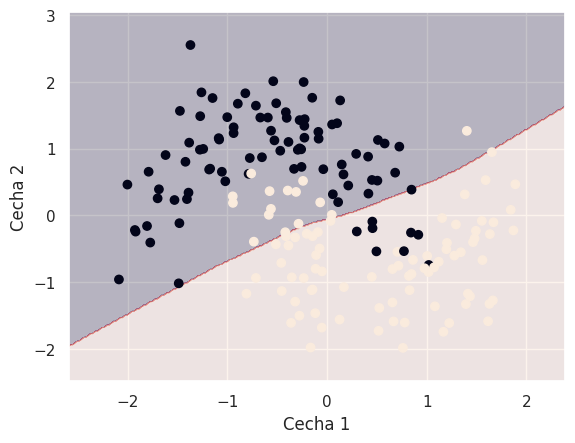

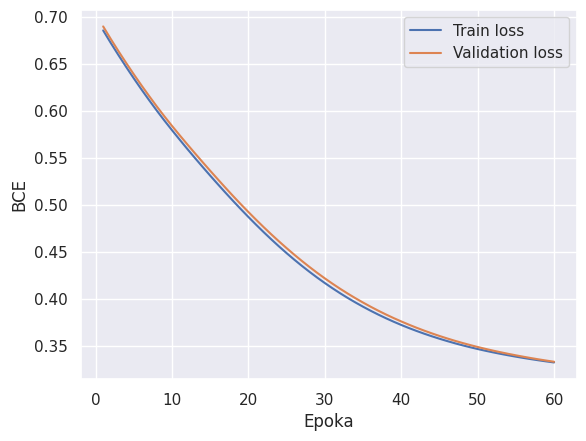

In [414]:
#Wykresy

xx, yy = np.meshgrid(
    np.linspace(X_val_scaled[:,0].min()-0.5, X_val_scaled[:,0].max()+0.5, 300),
    np.linspace(X_val_scaled[:,1].min()-0.5, X_val_scaled[:,1].max()+0.5, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
pred = tiny_MPL_model.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, pred, alpha=0.25)
plt.scatter(X_val_scaled[:,0], X_val_scaled[:,1], c=y_val)

plt.xlabel('Cecha 1')
plt.ylabel('Cecha 2')
plt.show()

epochs = [row['epoch'] for row in history_MPL]
train_loss = [row['train_loss'] for row in history_MPL]
val_loss = [row['val_loss'] for row in history_MPL]

plt.plot(epochs, train_loss, label='Train loss')
plt.plot(epochs, val_loss, label='Validation loss')

plt.xlabel('Epoka')
plt.ylabel('BCE')
plt.legend()
plt.show()

##Przykłady eksperymentalne



1.   50000 epok
2.   1000 epok
3.   seed próbek = 1
4.   seed próbek = 80



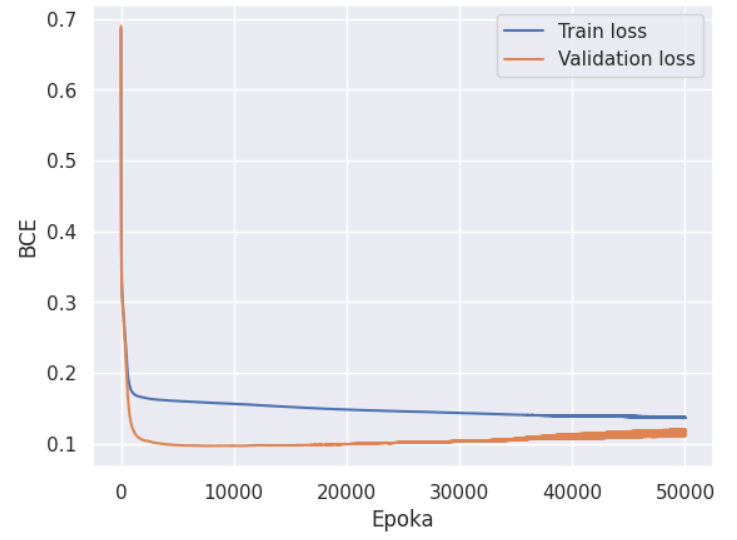

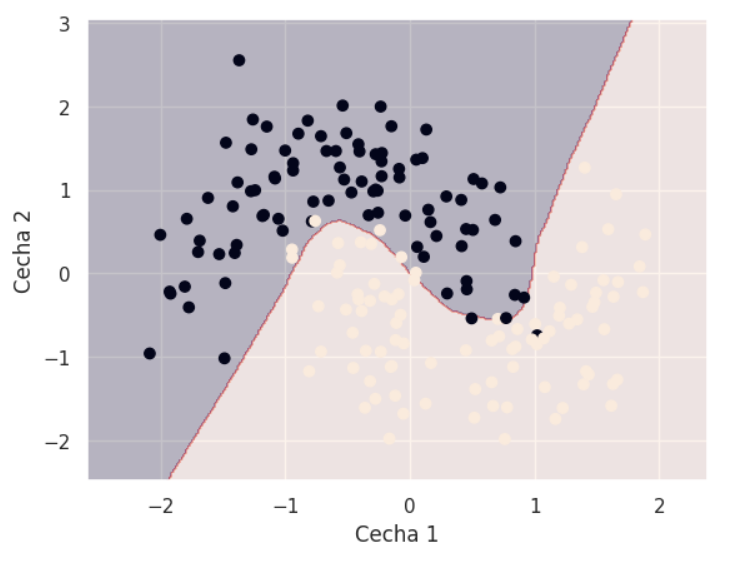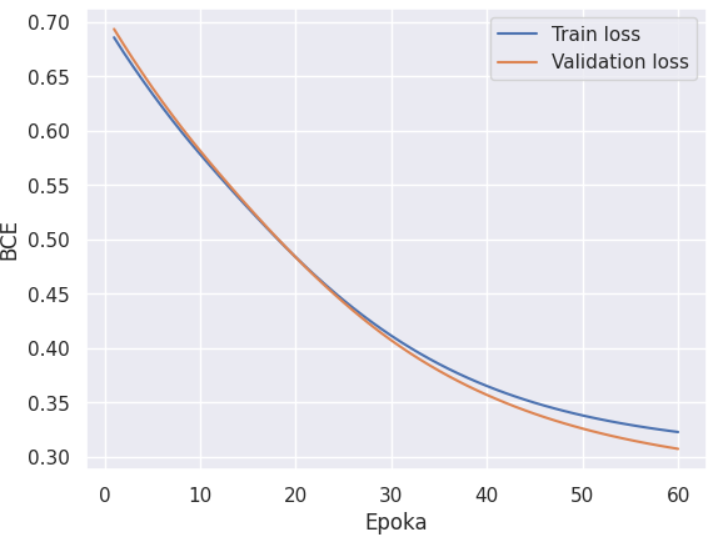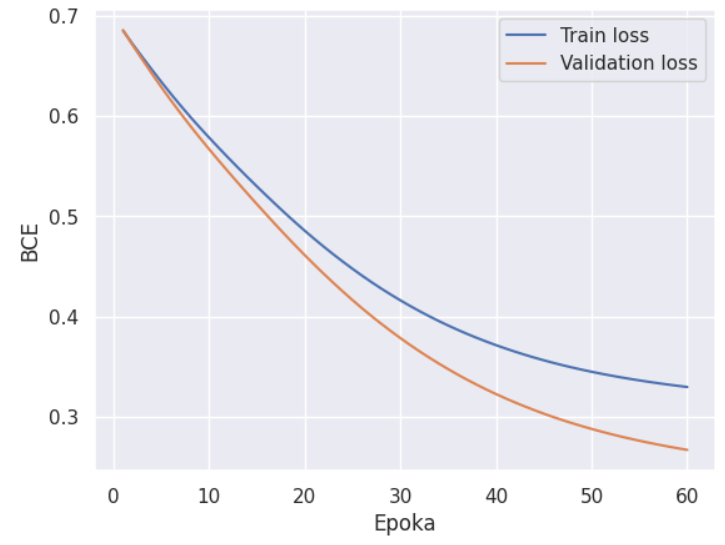

## 4. Kontrolowany eksperyment: dropout

Porównaj trzy konfiguracje: **dropout `0.0`, `0.2` i `0.4`**. Dropout stosuj po warstwach ukrytych. Poza wartością dropout utrzymuj ten sam podział danych, architekturę, optymalizator, współczynnik uczenia, batch size i maksymalną liczbę epok. Dzięki temu badany czynnik jest jasny.

Powtórz każdą konfigurację dla **trzech różnych ziaren inicjalizacji/treningu** (łącznie 9 treningów). Ziarno danych i podział pozostają stałe między wariantami. Zapisz, jak ustawiasz ziarna dla używanych bibliotek i frameworka.

Dla każdego treningu zapisz przebieg strat treningowej i walidacyjnej oraz accuracy i F1 na walidacji. Porównaj średni wynik i zmienność między trzema uruchomieniami. Nie wybieraj konfiguracji na podstawie wyniku testowego.

### Pytania do analizy

- Czy dropout zmienił różnicę między stratą treningową i walidacyjną?
- Która wartość dropout daje najlepszy wynik walidacyjny i czy przewaga jest powtarzalna?
- Czy mocniejsza regularyzacja zawsze poprawia wynik? Jak może wyglądać niedouczenie po zastosowaniu zbyt silnej regularyzacji?
- Czy wnioski pozostają podobne przy różnych ziarnach?

In [415]:
#Generacja
dropouts = [0.0, 0.2, 0.4]
seeds = [42, 5, 300]

results = []
histories = {}

for dropout in dropouts:
  for seed in seeds:
    model = TinyMLP(n_features=2, n_hidden_first=32, n_hidden_second=32,
                    seed=seed, activation_first='relu', activation_second='relu', dropout=dropout)
    history = model.fit(X_train_scaled, y_train, X_val_scaled, y_val, epochs=60, learning_rate=0.1)
    val_pred = model.predict(X_val_scaled)
    metrics = metrics_binary(y_val, val_pred)

    results.append({
      'dropout': dropout,
      'seed': seed,
      'accuracy': metrics['accuracy'],
      'f1': metrics['f1'],
      'train_loss': history[-1]['train_loss'],
      'val_loss': history[-1]['val_loss']
    })

    histories[(dropout, seed)] = history

for result in results:
  print(result, "gap: ", result['val_loss'] - result['train_loss'])


{'dropout': 0.0, 'seed': 42, 'accuracy': 0.8659217877094972, 'f1': 0.8620689655172413, 'train_loss': 0.3323696256039726, 'val_loss': 0.33312461778921804} gap:  0.00075499218524544
{'dropout': 0.0, 'seed': 5, 'accuracy': 0.8659217877094972, 'f1': 0.8636363636363636, 'train_loss': 0.34008387093773745, 'val_loss': 0.33581892428783827} gap:  -0.004264946649899182
{'dropout': 0.0, 'seed': 300, 'accuracy': 0.8547486033519553, 'f1': 0.8488372093023255, 'train_loss': 0.335271703462249, 'val_loss': 0.33833704092790967} gap:  0.003065337465660678
{'dropout': 0.2, 'seed': 42, 'accuracy': 0.8659217877094972, 'f1': 0.8620689655172413, 'train_loss': 0.33839296374340533, 'val_loss': 0.3402448727316147} gap:  0.001851908988209361
{'dropout': 0.2, 'seed': 5, 'accuracy': 0.8659217877094972, 'f1': 0.8636363636363636, 'train_loss': 0.3438901037739067, 'val_loss': 0.34006691605819145} gap:  -0.0038231877157152705
{'dropout': 0.2, 'seed': 300, 'accuracy': 0.8547486033519553, 'f1': 0.8488372093023255, 'train

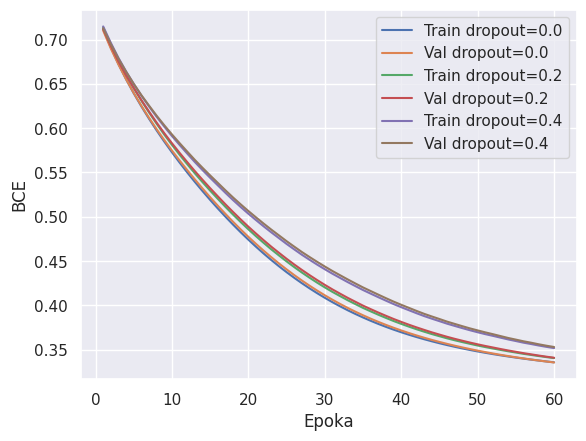

In [416]:
for dropout in dropouts:
    train_losses = []
    val_losses = []

    for seed in seeds:
        history = histories[(dropout, seed)]

        train_losses.append([row['train_loss'] for row in history])
        val_losses.append([row['val_loss'] for row in history])

    mean_train = np.mean(train_losses, axis=0)
    mean_val = np.mean(val_losses, axis=0)

    epochs = range(1, len(mean_train) + 1)

    plt.plot(epochs, mean_train, label=f'Train dropout={dropout}')
    plt.plot(epochs, mean_val, label=f'Val dropout={dropout}')

plt.xlabel('Epoka')
plt.ylabel('BCE')
plt.legend()
plt.show()


### Pytania do analizy

- Czy dropout zmienił różnicę między stratą treningową i walidacyjną? *Tak, wiekszy dropout zmiejsza gap, aczkolwiek zwiększa ogólny błąd*
- Która wartość dropout daje najlepszy wynik walidacyjny i czy przewaga jest powtarzalna? *0.0; tak*
- Czy mocniejsza regularyzacja zawsze poprawia wynik? Jak może wyglądać niedouczenie po zastosowaniu zbyt silnej regularyzacji? *W tym przypadku widzimy, że nie model ztaje się niedouczony względem 0 dropout*
- Czy wnioski pozostają podobne przy różnych ziarnach? *tak*

## 5. Wymagane wyniki i wykresy

W notebooku przedstaw:

1. krótki opis danych, podziału i przetwarzania;
2. wyniki baseline’u na walidacji;
3. krzywe straty treningowej i walidacyjnej dla modeli użytych do diagnozy;
4. porównanie wariantów dropout — wyniki dla wszystkich trzech powtórzeń oraz średnia i miara zmienności;
5. accuracy i F1 na zbiorze walidacyjnym;
6. wizualizacje granic decyzyjnych, z czytelną legendą i oznaczonym zbiorem punktów;
7. końcową ocenę accuracy i F1 na teście dla wybranej konfiguracji.

Podpisz osie, opisz serie na wykresach i podaj legendy. Każdy wykres powinien odpowiadać na konkretne pytanie eksperymentu.

## 6. Wybór modelu i test końcowy

Na podstawie wyłącznie wyników walidacyjnych wybierz konfigurację dropout. Możesz również ustalić sposób wyboru epoki na podstawie walidacyjnej straty. Zapisz uzasadnienie wyboru **przed** obliczeniem wyników testowych.

Następnie oceń wybraną konfigurację na zbiorze testowym i podaj accuracy oraz F1. Nie wracaj do zmieniania modelu po obejrzeniu testu. Jeśli po tej ocenie zmienisz model, test przestaje być niezależnym pomiarem końcowym.

Porównaj wynik testowy z walidacyjnym i skomentuj, czy różnica jest zgodna z oczekiwaniami. Nie traktuj małej różnicy jako gwarancji jakości na wszystkich przyszłych danych.

In [422]:
#Test

best_dropout = 0.0

final_model = TinyMLP(
    n_features=2,
    n_hidden_first=32,
    n_hidden_second=32,
    seed=42,
    activation_first='relu',
    activation_second='relu',
    dropout=best_dropout
)

final_history = final_model.fit(
    X_train_scaled, y_train,
    X_val_scaled, y_val,
    epochs=60,
    learning_rate=0.1
)

val_pred_final = final_model.predict(X_val_scaled)
val_metrics_final = metrics_binary(y_val, val_pred_final)

print('accuracy:', val_metrics_final['accuracy'])
print('f1:', val_metrics_final['f1'])

test_pred = final_model.predict(X_test_scaled)
test_metrics = metrics_binary(y_test, test_pred)

print('accuracy test:', test_metrics['accuracy'])
print('f1 test:', test_metrics['f1'])

print(
    'accuracy gap:',
    test_metrics['accuracy'] - val_metrics_final['accuracy']
)

print(
    'f1 gap:',
    test_metrics['f1'] - val_metrics_final['f1']
)

accuracy: 0.8659217877094972
f1: 0.8620689655172413
accuracy test: 0.8784530386740331
f1 test: 0.872093023255814
accuracy gap: 0.01253125096453589
f1 gap: 0.010024057738572623


## 7. Raport końcowy

Na końcu notebooka dodaj zwięzły raport zawierający:

- **Pytanie badawcze i hipotezę** — analiza efektywności różnych modeli uczenia maszynowego, zakładanie, że bardziej zaawansowany model będzie miał lepsze wskaźniki efektywności (f1 i accuracy)
- **Metodę** — wygenerowano 1200 probek za pomocą make_moons z poziomem szumu 0.25 i ziarnem 42. Dane zawierały dwie cechy wejściowe oraz dwie klasy. Zbiór podzielono na trening, walidacje i test 70:15:15, zestandaryzowano. Przeprowadzono badanie metod: max = wszyscy, liniowa (pojedynczy perceptron), pojedynczy perceptron, siec 3-warstwowa; w tym przypadku bardziej zaawansowany model dawał lepszy wynik
- **Diagnozę** — dla 60 epok model jest ciągle niedouczony; sprawdziłem dla 50000: dopiro miedzy 0 a 10000 zaczyna sie przuczenie
- **Eksperyment** — zmieniałem liczbę epok i próbek, poźniej seed - lekko zmieniało to metryki
- **Wnioski i ograniczenia** — czy wyniki wspierają hipotezę? - tak
Co mogło wpłynąć na rezultat? - przede wszystkim ograniczenie epok, niski szum, dostateczna separowalność danych



## Checklista wymagań

- [ ] 1200 przykładów, szum 0.25, ziarno danych 42.
- [ ] Stratyfikowany podział 70/15/15; brak przecieku z walidacji/testu do treningu lub skalowania.
- [ ] Naiwny baseline i model liniowy ocenione na walidacji.
- [ ] MLP ma minimum dwie warstwy ukryte po 32 neurony, ReLU i sigmoid na wyjściu.
- [ ] Pokazano i uzasadniono niedouczenie oraz przeuczenie.
- [ ] Porównano dropout 0.0/0.2/0.4 przy stałych pozostałych warunkach, do 60 epok.
- [ ] Każdy wariant uruchomiono z trzema ziarnami i podsumowano średnią oraz zmienność.
- [ ] Pokazano krzywe strat, granice decyzyjne i accuracy/F1 z walidacji.
- [ ] Test wykorzystano dopiero do jednokrotnej końcowej oceny wybranej konfiguracji.
- [ ] Raport zawiera uzasadnione wnioski i ograniczenia.

## Zasady pracy

- Pracuj w swoim notebooku i zapisuj go regularnie.
- Kod ma być uruchamialny od początku do końca w kolejności komórek.
- Opisuj eksperymenty własnymi słowami i wskazuj źródła użytych materiałów/kodu.
- Nie umieszczaj w notebooku haseł, tokenów ani prywatnych danych.
- Wymagania dotyczące terminu, formy oddania i punktacji przekazuje prowadzący osobno.